   # 01 Model
   Builds the modelling dataset from the SQL files in sql/, then trains and evaluates the bad review model.

In [33]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

con = duckdb.connect("../data/olist.duckdb")


## Setting up the SQL Files

In [34]:
# run a sql file against the database
def run_sql(file):
    con.execute(open(f"../sql/{file}").read())

## Clean orders
One row per delivered order with its items, payments and earliest review.

In [35]:
run_sql("clean_orders.sql")
# checking if each table has one row per order
for t in ["first_review", "order_items_agg", "order_payments_agg", "clean_orders"]:
    rows, orders = con.execute(f"select count(*), count(distinct order_id) from {t}").fetchone()
    print(f"{t:} rows={rows:}  orders={orders:}")

first_review rows=98673  orders=98673
order_items_agg rows=98666  orders=98666
order_payments_agg rows=99440  orders=99440
clean_orders rows=95658  orders=95658


Every table has one row per order, so joins won't duplicate orders. clean_orders keeps 95,658 delivered orders with valid dates and a review.

## Seller history
Each seller's earlier late deliveries and bad reviews, counting only outcomes already known at the order's handover.

In [36]:
run_sql("seller_history.sql")

# orders with seller history, and orders whose seller has no earlier known orders
print(con.execute("select count(*) from seller_history").fetchone()[0], "orders with history")
print(con.execute("""
    select count(*) from clean_orders o
    left join seller_history h on o.order_id = h.order_id
    where h.order_id is null
""").fetchone()[0], "orders with no history")

92620 orders with history
3038 orders with no history


In [37]:
# raw orders for one seller: handover, delivery and review dates with outcomes with an example seller
con.execute("""
    select order_id, handover_ts, delivered_ts, promised_ts,
           (delivered_ts > promised_ts)::int as late,
           review_answer_timestamp, review_score,
           (review_score <= 2)::int as bad_review
    from clean_orders
    where seller_id = 'c826c40d7b19f62a09e2d7c5e7295ee2'
    order by handover_ts
    limit 6
""").df()

,order_id,handover_ts,delivered_ts,promised_ts,late,review_answer_timestamp,review_score,bad_review
0,9d7f2c9f33008498700ffdc3162878fb,2017-08-28 19:03:48,2017-08-31 21:00:31,2017-09-18,0,2017-09-04 20:46:52,5,0
1,392240bf6b91914830b77ae8572cc0b7,2017-09-05 21:53:43,2017-09-19 19:53:04,2017-09-28,0,2017-09-21 02:07:57,1,1
2,c501bcc74df5ad09bcabd7774b6ae383,2017-09-19 20:24:36,2017-10-05 11:33:35,2017-10-06,0,2017-10-09 11:54:37,5,0
3,c1e50c50037af907b9099da2c948e109,2017-09-25 20:32:44,2017-10-02 18:07:56,2017-10-18,0,2017-10-04 16:18:34,4,0
4,51427a59ed7cf06820364d94af7a6f7a,2017-09-26 20:33:02,2017-10-11 15:39:15,2017-10-13,0,2017-10-16 17:32:20,4,0
5,8c4bbf2fb218d1ac2fc4fc082c238d64,2017-10-06 21:03:55,2017-10-23 21:11:32,2017-11-07,0,2017-10-24 23:32:51,4,0


In [38]:
# history for one seller over time: counts grow only once outcomes are known
con.execute("""
    select o.handover_ts, h.seller_past_orders, h.seller_past_late, h.seller_past_reviews, h.seller_past_bad
    from clean_orders o
    left join seller_history h on o.order_id = h.order_id
    where o.seller_id = 'c826c40d7b19f62a09e2d7c5e7295ee2'
    order by o.handover_ts
    limit 6
""").df()

,handover_ts,seller_past_orders,seller_past_late,seller_past_reviews,seller_past_bad
0,2017-08-28 19:03:48,<NA>,<NA>,<NA>,<NA>
1,2017-09-05 21:53:43,1,0,1,0
2,2017-09-19 20:24:36,2,0,1,0
3,2017-09-25 20:32:44,2,0,2,1
4,2017-09-26 20:33:02,2,0,2,1
5,2017-10-06 21:03:55,4,0,3,1


The history only counts what was already known at each handover. When this seller's third order was handed over on 19 Sep, the second order had just been delivered but its 1-star review was only written on 21 Sep, so it is not counted yet; it appears from the fourth order onwards. The model therefore only uses information that would really be available at the time of prediction.

## Train and test periods
The model is trained on earlier orders and tested on later ones, so the evaluation reflects how it would be used on future orders.

| Period | Handover dates | Used for |
|---|---|---|
| Train | 1 Jan 2017 to 31 Mar 2018 | fitting the model and calculating the smoothing averages |
| Test | 1 Apr 2018 to 31 Aug 2018 | evaluating the model only |

The cutoff of 1 April 2018 gives roughly two thirds of orders for training and one third for testing. Anything calculated from the data before modelling, such as the smoothing averages below, uses training orders only, so nothing from the test period influences the model.

In [39]:
# average late and bad review rates in the training period
con.execute("""
    select count(*) as orders,
           sum((delivered_ts > promised_ts)::int) as late_orders,
           round(100 * avg((delivered_ts > promised_ts)::int), 1) as late_pct,
           sum((review_score <= 2)::int) as bad_reviews,
           round(100 * avg((review_score <= 2)::int), 1) as bad_review_pct
    from clean_orders
    where handover_ts >= timestamp '2017-01-01'
      and handover_ts < timestamp '2018-04-01'
""").df()

,orders,late_orders,late_pct,bad_reviews,bad_review_pct
0,62833,5607.0,8.9,8734.0,13.9


8.9% of training orders were delivered late and 13.9% got a bad review. These are rounded to 9% and 14% and used as the smoothing averages in `feature_table.sql`

## Smoothing formula

For an order handed over at time $t$, by seller $s$:

$$
\hat{r}_{s,t} = \frac{x_{s,t} + k \cdot \bar{r}}{n_{s,t} + k}
$$

| Symbol | Meaning | Value |
|---|---|---|
| $n_{s,t}$ | seller's earlier orders whose outcome was known at $t$ | from seller_history |
| $x_{s,t}$ | how many of those were late (or got a bad review) | from seller_history |
| $\bar{r}$ | average rate in the training period | 0.09 late, 0.14 bad review |
| $k$ | weight given to the average, in "orders" | 10 |

It can also be written as a weighted average of the seller's own rate and the overall average:

$$
\hat{r}_{s,t} = w \cdot \frac{x_{s,t}}{n_{s,t}} + (1 - w) \cdot \bar{r}, \qquad w = \frac{n_{s,t}}{n_{s,t} + k}
$$

The more orders a seller has, the closer $w$ gets to 1 and the more their own rate counts. With no orders, $w = 0$ and the rate equals the average. Statistically, this is the posterior mean of a Beta-Binomial model with a $\text{Beta}(k\bar{r},\ k(1-\bar{r}))$ prior, the same idea as a Bayesian average or smoothed target encoding.

**Worked example (late rate, $\bar{r} = 0.09$, $k = 10$)**

A seller has 20 earlier orders known at handover, of which 6 arrived late.

1. Raw rate: $6 / 20 = 30\%$
2. Weight on the seller's own rate: $w = 20 / (20 + 10) = 0.67$
3. Smoothed rate: $0.67 \times 30\% + 0.33 \times 9\% = 23.0\%$

Same result from the first formula: $(6 + 10 \times 0.09) / (20 + 10) = 6.9 / 30 = 23.0\%$.

| Seller | $n$ | $x$ | Raw rate | $w$ | Smoothed |
|---|---|---|---|---|---|
| New | 0 | 0 | none | 0.00 | 9.0% |
| 1 order, late | 1 | 1 | 100% | 0.09 | 17.3% |
| 2 orders, on time | 2 | 0 | 0% | 0.17 | 7.5% |
| 20 orders, 6 late | 20 | 6 | 30% | 0.67 | 23.0% |
| 500 orders, 40 late | 500 | 40 | 8% | 0.98 | 8.0% |

A seller with one late order out of one is treated as somewhat worse than average (17%), not as always late (100%). A seller with 500 orders keeps their real rate.

## Feature table
One row per delivered order, observed at the moment the seller hands the parcel to the carrier. Every feature is known at that moment.

| Group | Features | Why |
|---|---|---|
| Seller dispatch | dispatch_days_late (capped at ±30 days), dispatch_late, days_to_handover | late dispatch doubles the bad review rate |
| Delivery promise | promised_days, days_left_to_promise | few days left at handover means a late delivery is likely |
| Basket | n_items, n_sellers, total_price, freight_ratio | larger or costly-to-ship orders have more that can go wrong |
| Geography | same_state, customer_state | orders crossing states travel further |
| Product | category ('unknown' if missing, Portuguese name if no translation), missing_listing, photos | some categories and incomplete listings get more bad reviews |
| Seller history | seller_past_orders, seller_past_late_rate, seller_past_bad_rate (smoothed) | a seller's track record predicts future problems |
| Target | bad_review (1 = 1-2 stars) | what the model predicts |

Not included, because they are only known after handover:
- the actual delivery date, whether the order arrived late, and the review text. 
- Payment data is left out as it adds nothing beyond price and freight. 
- Only handovers between Jan 2017 and Aug 2018 are kept.

In [40]:
run_sql("feature_table.sql")
features = con.execute("select * from feature_table").df()

# size, bad review rate, date range and missing values
print(features.shape )
print('Date range:', features.handover_ts.min(), "to", features.handover_ts.max())
print("missing values:", features.isnull().sum().sum())
features.head()

(95392, 20)
Date range: 2017-01-06 12:43:41 to 2018-08-31 15:25:00
missing values: 0


,order_id,handover_ts,dispatch_days_late,dispatch_late,days_to_handover,promised_days,days_left_to_promise,n_items,n_sellers,total_price,freight_ratio,same_state,customer_state,category,missing_listing,photos,seller_past_orders,seller_past_late_rate,seller_past_bad_rate,bad_review
0,36af5b0b0ededbf6f30d1d809f05536b,2018-06-04 14:10:00,-7.250000,0,0.750000,32,30.416667,1,1,115.0,0.136174,1,MG,fashion_bags_accessories,0,6,30,0.072500,0.152381,0
1,520563861deb0acf3b7ab8295ced6e01,2018-01-18 12:52:07,-3.625000,0,3.833333,32,27.500000,1,1,139.0,0.215899,0,BA,auto,0,1,272,0.070567,0.072857,0
2,459aa8ae0e09ae140ba9f75c1f429524,2017-04-11 14:28:46,-5.583333,0,2.791667,30,26.416667,1,1,44.0,0.364773,0,RJ,baby,0,2,6,0.056250,0.087500,0
3,474cefe70ac457aaa468b62e07818c5e,2018-01-27 01:42:53,-4.375000,0,38.666667,56,16.958333,1,1,339.0,0.031180,1,SP,consoles_games,0,2,19,0.203448,0.174194,0
4,df85286f77ee8760333080a6b3bb97d8,2018-02-14 19:51:40,-0.875000,0,3.166667,26,22.208333,1,1,119.9,0.121518,0,SP,health_beauty,0,2,77,0.033333,0.051765,0


In [41]:
# sellers with no earlier orders should get exactly the smoothing averages
features[features.seller_past_orders == 0][["seller_past_late_rate", "seller_past_bad_rate"]].value_counts()

seller_past_late_rate  seller_past_bad_rate
0.09                   0.140000                4340
                       0.218182                   9
                       0.283333                   2
                       0.127273                   2
                       0.385714                   1
Name: count, dtype: int64

## Train/test split
Orders are split by handover date using the periods defined above: before 1 April 2018 for training, from 1 April 2018 for testing.

In [42]:
# split by handover date
split_date = pd.Timestamp("2018-04-01")
train = features[features.handover_ts < split_date].copy()
test = features[features.handover_ts >= split_date].copy()

# size and bad review rate of each part
pd.DataFrame({
    "orders": [len(train), len(test)],
    "bad_reviews": [train.bad_review.sum(), test.bad_review.sum()],
    "bad_review_pct": [train.bad_review.mean() * 100, test.bad_review.mean() * 100],
}, index=["train", "test"]).round(1)

,orders,bad_reviews,bad_review_pct
train,62833,8734,13.9
test,32559,3470,10.7


The test period has fewer bad reviews (10.7% vs 13.9%) because training includes the Feb-Mar 2018 delivery problems.

## Baseline: flag late dispatch
A simple rule the business could use without a model: flag every order the seller handed to the carrier after the shipping deadline.

In [43]:
# baseline: flag orders dispatched after the seller's deadline
flagged = test[test.dispatch_late == 1]
print("orders flagged:", round(test.dispatch_late.mean() * 100, 1), "%")
print("bad review rate among flagged:", round(flagged.bad_review.mean() * 100, 1), "%")
print("share of all bad reviews caught:", round(flagged.bad_review.sum() / test.bad_review.sum() * 100, 1), "%")

orders flagged: 7.9 %
bad review rate among flagged: 21.1 %
share of all bad reviews caught: 15.6 %


The rule flags 7.9% of orders, and 21.1% of those get a bad review, about twice the overall rate of 10.7%. It catches 15.6% of all bad reviews.

In [44]:
features.columns

Index(['order_id', 'handover_ts', 'dispatch_days_late', 'dispatch_late',
       'days_to_handover', 'promised_days', 'days_left_to_promise', 'n_items',
       'n_sellers', 'total_price', 'freight_ratio', 'same_state',
       'customer_state', 'category', 'missing_listing', 'photos',
       'seller_past_orders', 'seller_past_late_rate', 'seller_past_bad_rate',
       'bad_review'],
      dtype='str')

## Multicollinearity check 

In [45]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

def checking_vif(predictors):
    vif = pd.DataFrame()
    vif["feature"] = predictors.columns
    vif["VIF"] = [
        variance_inflation_factor(predictors.values, i)
        for i in range(len(predictors.columns))
    ]
    return vif.sort_values("VIF", ascending=False)


In [46]:

# numeric features considered for the model
feat_col = ['dispatch_days_late', 'dispatch_late',
       'days_to_handover', 'promised_days', 'days_left_to_promise', 'n_items',
       'n_sellers', 'total_price', 'freight_ratio', 'same_state', 'missing_listing', 'photos',
       'seller_past_orders', 'seller_past_late_rate', 'seller_past_bad_rate']

checking_vif(sm.add_constant(train[feat_col]))

,feature,VIF
5,days_left_to_promise,1258.868391
4,promised_days,1209.110931
3,days_to_handover,257.624377
1,dispatch_days_late,2.154688
2,dispatch_late,1.715833
10,same_state,1.493313
15,seller_past_bad_rate,1.268737
14,seller_past_late_rate,1.253480
8,total_price,1.201377
9,freight_ratio,1.195841


- days_left_to_promise, promised_days and days_to_handover are linked by definition (promised days = days to handover + days left after handover), which gives VIFs above 250. Dropping days_left_to_promise removes this, and every remaining feature has a VIF below 2.3.

- seller_past_orders is not collinear (VIF 1.0) but is also left out. It is a running count that will always increases over time, so it can confuse the model when applied to a later period. A seller's performance is already captured by the smoothed past late rate and past bad review rate.

In [47]:
# vif after dropping days_left_to_promise and seller_past_orders
checking_vif(sm.add_constant(train[[c for c in feat_col if c not in ["days_left_to_promise", "seller_past_orders"]]]))

,feature,VIF
3,days_to_handover,2.201055
1,dispatch_days_late,2.153423
2,dispatch_late,1.712892
4,promised_days,1.707800
9,same_state,1.491917
13,seller_past_bad_rate,1.267057
12,seller_past_late_rate,1.242965
7,total_price,1.194113
8,freight_ratio,1.193652
5,n_items,1.124556


Every feature is within the VIF range of 1-5 post dropping days_left_to_promise and promise_days

In [48]:
features.columns

Index(['order_id', 'handover_ts', 'dispatch_days_late', 'dispatch_late',
       'days_to_handover', 'promised_days', 'days_left_to_promise', 'n_items',
       'n_sellers', 'total_price', 'freight_ratio', 'same_state',
       'customer_state', 'category', 'missing_listing', 'photos',
       'seller_past_orders', 'seller_past_late_rate', 'seller_past_bad_rate',
       'bad_review'],
      dtype='str')

In [49]:
feat_col = [ 'dispatch_days_late', 'dispatch_late',
       'days_to_handover','promised_days', 'n_items',
       'n_sellers', 'total_price', 'freight_ratio', 'same_state',
       'customer_state', 'category', 'missing_listing', 'photos', 'seller_past_late_rate', 'seller_past_bad_rate']

target = "bad_review"

## Logistic regression
Logistic regression is used because the main drivers are simple, its coefficients can be explained in plain terms, and its scores can be read as probabilities for estimating campaign impact.

In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

categorical = ["customer_state", "category"]
numeric = [c for c in feat_col if c not in categorical]

# inputs and target
X_train = train[feat_col].copy()
X_test = test[feat_col].copy()
y_train = train[target]
y_test = test[target]


# scale numeric features using training data only
scaler = StandardScaler()
X_train[numeric] = scaler.fit_transform(X_train[numeric])
X_test[numeric] = scaler.transform(X_test[numeric])

# one 0/1 column per category, test aligned to the training columns
X_train = pd.get_dummies(X_train, columns=categorical, dtype=int)
X_test = pd.get_dummies(X_test, columns=categorical, dtype=int).reindex(columns=X_train.columns, fill_value=0)

# fit and score
model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)
test["score"] = model.predict_proba(X_test)[:, 1]
# risk score for every training order, needed to compare train and test
train["score"] = model.predict_proba(X_train)[:, 1]

In [51]:
# average score and actual bad review rate in each period
pd.DataFrame({
    "orders": [len(train), len(test)],
    "avg_score_pct": [train.score.mean() * 100, test.score.mean() * 100],
    "actual_bad_review_pct": [train.bad_review.mean() * 100, test.bad_review.mean() * 100],
}, index=["train", "test"]).round(1)

,orders,avg_score_pct,actual_bad_review_pct
train,62833,13.9,13.9
test,32559,14.5,10.7


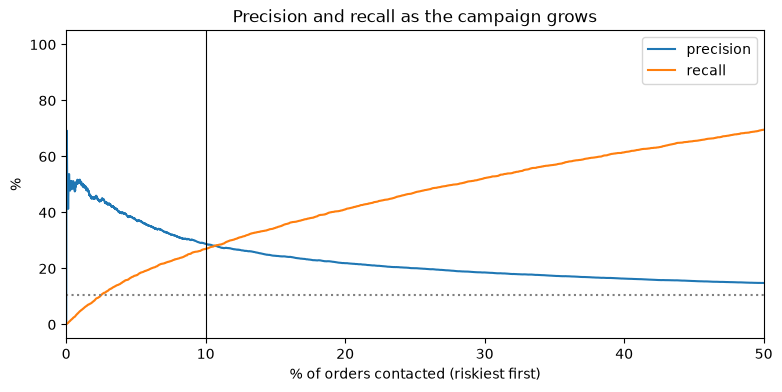

In [52]:
# test orders ranked from riskiest to safest
ranked = test.sort_values("score", ascending=False).reset_index(drop=True)

# precision and recall if we contact the top k orders
ranked["pct_contacted"] = (ranked.index + 1) / len(ranked) * 100
ranked["precision"] = ranked.bad_review.cumsum() / (ranked.index + 1) * 100
ranked["recall"] = ranked.bad_review.cumsum() / ranked.bad_review.sum() * 100

# plot both against campaign size
ax = ranked.plot(x="pct_contacted", y=["precision", "recall"], xlim=(0, 50), figsize=(9, 4),
                 title="Precision and recall as the campaign grows")
ax.axhline(test.bad_review.mean() * 100, color="grey", linestyle=":")
ax.axvline(10, color="black", linewidth=0.8)
ax.set_xlabel("% of orders contacted (riskiest first)")
ax.set_ylabel("%")
plt.show()

Here we can observe that, the precision falls steeply till 10% and then the slope is much more gradual and slowly drifts towards the baseline rate of 10.7%(represented with a dotted_line). So this is a good cut-off point.

## Model vs baseline rule
The baseline rule flags every order dispatched late, which is 7.9% of test orders. The fairest comparison is the model contacting the same number of orders.

In [53]:
# baseline rule: orders dispatched after the seller's deadline
rule = test[test.dispatch_late == 1]
rule_share = len(rule) / len(test) * 100

# model contacting the same number of orders as the rule, using the ranked table from above
model_same_size = ranked.head(len(rule))

# random choice of the same number of orders: precision is the overall rate, recall equals the share contacted
pd.DataFrame({
    "orders_contacted_pct": [rule_share, rule_share, rule_share],
    "precision_pct": [test.bad_review.mean() * 100,
                      rule.bad_review.mean() * 100,
                      model_same_size.bad_review.mean() * 100],
    "recall_pct": [rule_share,
                   rule.bad_review.sum() / test.bad_review.sum() * 100,
                   model_same_size.bad_review.sum() / test.bad_review.sum() * 100],
}, index=["random", "baseline rule (late dispatch)", "model"]).round(1)

,orders_contacted_pct,precision_pct,recall_pct
random,7.9,10.7,7.9
baseline rule (late dispatch),7.9,21.1,15.6
model,7.9,31.6,23.3


All three approaches contact the same 7.9% of test orders. Chosen at random, 10.7% would get a bad review, reaching 7.9% of all bad reviews. The late-dispatch rule doubles this (21.1% precision, 15.6% recall), and the model triples it (31.6% precision, 23.3% recall). Late dispatch is a useful signal on its own, but combining it with handover time, basket size, seller history and region identifies risky orders much better.

## Train vs test at the chosen cut-off
The cut-off is set on training data as the score that flags the riskiest 10% of orders, then applied unchanged to test, as it would be in production.

In [54]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# score that flags the riskiest 10% of training orders
cutoff = train.score.quantile(0.90)
print("score cut-off:", round(cutoff, 4))

# metrics for one period at the cut-off
def summarize(df, label):
    flag = (df.score >= cutoff).astype(int)
    return pd.DataFrame({
        "flagged_pct": [flag.mean() * 100],
        "auc": [roc_auc_score(df.bad_review, df.score)],
        "accuracy": [accuracy_score(df.bad_review, flag)],
        "precision": [precision_score(df.bad_review, flag)],
        "recall": [recall_score(df.bad_review, flag)],
        "f1": [f1_score(df.bad_review, flag)],
    }, index=[label])

pd.concat([summarize(train, "train"), summarize(test, "test")]).round(3)

score cut-off: 0.2227


,flagged_pct,auc,accuracy,precision,recall,f1
train,10.001,0.671,0.830,0.343,0.247,0.287
test,11.143,0.668,0.843,0.274,0.286,0.280


In [55]:
# test outcomes vs flags at the cut-off
pd.DataFrame(
    confusion_matrix(test.bad_review, (test.score >= cutoff).astype(int)),
    index=["actual: no bad review", "actual: bad review"],
    columns=["not flagged", "flagged"],
)

,not flagged,flagged
actual: no bad review,26455,2634
actual: bad review,2476,994


## Calibration
The scores are used to rank orders, next part also uses them to estimate how many bad reviews are at stake, so the predicted probabilities should match actual rates. Orders are split into ten equal bands by score, and the average predicted risk is compared with the actual bad review rate in each band, for train and test.

In [56]:
# predicted vs actual bad review rate in ten equal groups of orders (deciles), lowest to highest score
def calibration_table(df):
    decile = pd.qcut(df.score.rank(method="first"), 10, labels=range(1, 11))
    table = df.groupby(decile, observed=True).agg(
        orders=("score", "size"),
        predicted_pct=("score", "mean"),
        actual_pct=("bad_review", "mean"),
    )
    table.index.name = "decile"
    table[["predicted_pct", "actual_pct"]] *= 100
    return table.round(1)

pd.concat([calibration_table(train), calibration_table(test)], axis=1, keys=["train", "test"])

train                            test                         
       orders predicted_pct actual_pct orders predicted_pct actual_pct
decile                                                                
1        6284           6.4        6.0   3256           6.7        5.5
2        6283           7.9        6.9   3256           8.3        5.5
3        6283           8.9        8.6   3256           9.3        6.5
4        6283           9.8        9.5   3256          10.3        6.9
5        6284          10.9       10.5   3256          11.4        8.0
6        6283          12.2       12.4   3255          12.6        8.6
7        6283          13.8       14.3   3256          14.2        9.8
8        6283          16.0       16.4   3256          16.5       11.9
9        6283          19.5       20.1   3256          20.2       15.0
10       6284          33.7       34.3   3256          35.6       28.8

In [57]:
print(round(calibration_table(test)['predicted_pct'].mean(), 2))
print(round(calibration_table(test)['actual_pct'].mean(), 2))


14.51
10.65


In training, predicted and actual rates match closely in every decile (33.7% predicted vs 34.3% actual in the riskiest), so the model is well calibrated on the period it learned from.

In test, the ranking still holds: the actual bad review rate rises from 5.5% in decile 1 to 28.8% in decile 10, and the riskiest decile stands out at almost twice the next one (15.0%). However, predictions are 1 to 7 percentage points higher in every decile (35.6% predicted vs 28.8% actual in decile 10), this is because the test months had fewer bad reviews than the training period, which included the Feb-Mar 2018 delivery problems.

So the scores can be trusted to choose whom to contact, but not as exact probabilities. We will use the actual 28.8% to estimate the impact of targeting the top decile, and in production the model should be recalibrated regularly as delivery conditions change.

In [58]:
# odds ratio per one standard deviation increase in each numeric feature
coefs = pd.Series(model.coef_[0], index=X_train.columns)
numeric_coefs = coefs[numeric].sort_values(ascending=False)
pd.DataFrame({"coefficient": numeric_coefs, "odds_ratio": np.exp(numeric_coefs)}).round(2)

,coefficient,odds_ratio
days_to_handover,0.24,1.27
n_items,0.20,1.22
seller_past_bad_rate,0.16,1.17
n_sellers,0.16,1.17
dispatch_days_late,0.07,1.07
total_price,0.05,1.05
dispatch_late,0.04,1.04
missing_listing,0.03,1.03
freight_ratio,0.02,1.02
seller_past_late_rate,0.02,1.02


In [59]:
import statsmodels.api as sm

# unregularised logistic regression on the scaled numeric features, for confidence intervals and p-values
numeric_sig = [c for c in numeric if c != "missing_listing"]
logit = sm.Logit(y_train.values, sm.add_constant(X_train[numeric_sig])).fit(disp=0)

pd.DataFrame({
    "odds_ratio": np.exp(logit.params),
    "ci_low": np.exp(logit.conf_int()[0]),
    "ci_high": np.exp(logit.conf_int()[1]),
    "p_value": logit.pvalues,
}).drop("const").sort_values("odds_ratio", ascending=False).round(3)

,odds_ratio,ci_low,ci_high,p_value
days_to_handover,1.237,1.198,1.277,0.000
n_items,1.214,1.189,1.238,0.000
seller_past_bad_rate,1.188,1.160,1.217,0.000
n_sellers,1.169,1.149,1.190,0.000
dispatch_days_late,1.090,1.053,1.129,0.000
total_price,1.053,1.029,1.077,0.000
dispatch_late,1.042,1.015,1.071,0.002
freight_ratio,1.030,1.006,1.055,0.015
seller_past_late_rate,1.007,0.983,1.032,0.555
photos,0.973,0.950,0.996,0.024


- The main drivers are all statistically clear (p < 0.01): days to handover, number of items and sellers, the seller's past bad review rate, dispatch delay and price raise the risk, while same-state shipping and a longer delivery promise lower it. 
- The seller's past late rate is not significant once these are known (p = 0.55), as late sellers already show up through their dispatch timing and bad review history.

## Leakage check
To check the model is not quietly using future information, the same model is retrained with one leaky feature added: whether the order was actually delivered late, which is only known after handover. A large jump in performance shows how much the model would gain from information it cannot have when the prediction is made.

In [60]:
# actual late delivery, only known after handover
late_flag = con.execute("select order_id, (delivered_ts > promised_ts)::int as delivered_late from clean_orders").df()
late_train = train[["order_id"]].merge(late_flag, on="order_id", how="left").delivered_late.values
late_test = test[["order_id"]].merge(late_flag, on="order_id", how="left").delivered_late.values

# same inputs plus the leaky flag, scaled with training values
X_train_leaky = X_train.copy()
X_test_leaky = X_test.copy()
X_train_leaky["delivered_late"] = (late_train - late_train.mean()) / late_train.std()
X_test_leaky["delivered_late"] = (late_test - late_train.mean()) / late_train.std()

# retrain and score with the leaky flag
leaky_model = LogisticRegression(max_iter=2000).fit(X_train_leaky, y_train)
leaky_scores = leaky_model.predict_proba(X_test_leaky)[:, 1]

# compare ranking quality and top-10% precision
top_n = int(len(test) * 0.10)
pd.DataFrame({
    "test_auc": [roc_auc_score(y_test, test.score), roc_auc_score(y_test, leaky_scores)],
    "top_10pct_precision": [test.nlargest(top_n, "score").bad_review.mean() * 100,
                            test.assign(score=leaky_scores).nlargest(top_n, "score").bad_review.mean() * 100],
}, index=["handover features only", "with actual late delivery (leaky)"]).round(3)

,test_auc,top_10pct_precision
handover features only,0.668,28.817
with actual late delivery (leaky),0.721,38.679


## Where the model is weak
- It cannot see causes that happen after handover or are not recorded: product quality, damage in transit, the courier's last mile. With complete info of late delivery, top-10% precision would only reach about 39%.
- It over-predicts in calmer periods: its average predicted risk in test is 14.5% against an actual 10.7%, so probabilities should be recalibrated before being used to estimate volumes.
- New sellers have no track record, so their seller rates default to the average.
- Multi-seller orders (1.3%) are linked to the first item's seller, which may not be the one that causes a delay.
- It predicts risk, not the effect of an intervention: a high score does not mean contact would change the review, which is why the campaign is tested with an experiment.

# Campaign Sizing

## Target group
- The campaign targets the riskiest 10% of orders at carrier handover. Its size and real bad review rate come from the test period, which reflects the most recent conditions.

In [61]:
# riskiest 10% of test orders and the number of test months
top_decile = ranked.head(int(len(ranked) * 0.10))
months = test.handover_ts.dt.to_period("M").nunique()

# monthly size of the target group and its actual bad review rate
target_per_month = len(top_decile) / months
bad_rate_target = top_decile.bad_review.mean()

print("test months:", months)
print("orders targeted per month:", round(target_per_month))
print("actual bad review rate in target group:", round(bad_rate_target * 100, 1), "%")
print("bad reviews per month in target group:", round(target_per_month * bad_rate_target))

test months: 5
orders targeted per month: 651
actual bad review rate in target group: 28.8 %
bad reviews per month in target group: 188


About 651 orders a month would be contacted, of which around 188 would otherwise get a bad review. The actual rate (28.8%) is used rather than the models predicted rate, which runs about 6 points high in this period.

## Expected impact
The campaign's effect is unknown before testing, so impact is shown as a range under stated assumptions:
- **Effect:** the campaign prevents 10% (low), 20% (mid) or 30% (high) of bad reviews among contacted orders.
- **Cost:** a $5 goodwill voucher per contacted order; the message itself is automated and treated as free. (Assumption: the voucher is only redeemed on a future purchase, so this is an upper bound.)
- **Value:** the commercial value of avoiding a bad review is not in the data, so the output is the cost per bad review prevented, which the business can compare with its own estimate.

In [62]:
# assumptions
voucher_cost = 5
effects = {"low": 0.10, "mid": 0.20, "high": 0.30}

# median value of targeted orders (items plus freight), as a reference for what a bad review might cost
order_value = con.execute("select order_id, total_price + total_freight as order_value from clean_orders").df()
median_target_value = top_decile.merge(order_value, on="order_id").order_value.median()
print("median value of a targeted order: $", round(median_target_value))

# bad reviews prevented, monthly cost and cost per bad review prevented under each assumption
bad_per_month = target_per_month * bad_rate_target
monthly_cost = target_per_month * voucher_cost
impact = pd.DataFrame({
    "effect_pct": [e * 100 for e in effects.values()],
    "bad_reviews_prevented_per_month": [bad_per_month * e for e in effects.values()],
    "monthly_cost_$": [monthly_cost] * len(effects),
    "cost_per_bad_review_prevented_$": [monthly_cost / (bad_per_month * e) for e in effects.values()],
}, index=effects.keys())

# cost per bad review prevented compared with the value of one targeted order
impact["cost_vs_order_value_pct"] = impact["cost_per_bad_review_prevented_$"] / median_target_value * 100
impact.round(0)

median value of a targeted order: $ 164


,effect_pct,bad_reviews_prevented_per_month,monthly_cost_$,cost_per_bad_review_prevented_$,cost_vs_order_value_pct
low,10.0,19.0,3255.0,174.0,106.0
mid,20.0,38.0,3255.0,87.0,53.0
high,30.0,56.0,3255.0,58.0,35.0


Targeted orders have a median value of $164. 
- At a 20% effect, the campaign prevents around 38 bad reviews a month for about $3,255, which is $87 per bad review avoided, about half the value of one targeted order. Even at the low estimate it costs roughly one order's value per bad review avoided. So if a bad review typically costs the business at least half a future order, through a lost repeat purchase or weaker seller ranking, the campaign pays off at the mid estimate.

## Experiment design
Each week, orders are scored at carrier handover and the riskiest 10% become eligible. Eligible orders are randomly split 50/50 between treatment (proactive message and $5 voucher) and control (no contact). Randomising within the eligible group means the only systematic difference between the groups is the campaign, so any difference in bad reviews can be attributed to it.

- **Primary metric:** bad review rate (1-2 stars) in treatment vs control.
- **Guardrails:** review response rate (fewer reviews could look like fewer bad reviews), repeat purchase within 90 days, and voucher cost per order.

The calculation below shows how many eligible orders are needed to detect different effect sizes, with 80% power at a 5% significance level.

In [63]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

# orders needed per group to detect each relative reduction in the bad review rate
rows = []
for reduction in [0.10, 0.15, 0.20, 0.25, 0.30]:
    treated_rate = bad_rate_target * (1 - reduction)
    effect = proportion_effectsize(bad_rate_target, treated_rate)
    per_group = np.ceil(NormalIndPower().solve_power(effect_size=effect, alpha=0.05, power=0.8, ratio=1))
    rows.append({
        "relative_reduction_pct": reduction * 100,
        "control_rate_pct": bad_rate_target * 100,
        "treatment_rate_pct": treated_rate * 100,
        "orders_per_group": per_group,
        "total_orders": 2 * per_group,
        "months_needed": 2 * per_group / target_per_month,
    })
pd.DataFrame(rows).round(1)

,relative_reduction_pct,control_rate_pct,treatment_rate_pct,orders_per_group,total_orders,months_needed
0,10.0,28.8,25.9,3756.0,7512.0,11.5
1,15.0,28.8,24.5,1641.0,3282.0,5.0
2,20.0,28.8,23.1,906.0,1812.0,2.8
3,25.0,28.8,21.6,568.0,1136.0,1.7
4,30.0,28.8,20.2,386.0,772.0,1.2


At about 650 eligible orders a month, a 20% reduction in bad reviews (from 28.8% to 23.1%) can be detected in under three months, with about 900 orders per group (1,812 in total). Smaller effects take much longer: a 10% reduction would need about 3,750 orders per group and nearly a year. The test is therefore planned to detect a 20% reduction, which is also the mid estimate in the impact range. Treatment and control run over the same weeks, so seasonal swings such as Black Friday affect both groups equally.

**Decision rule**
- **Roll out:** bad reviews fall significantly in treatment, the guardrails hold (review response rate, repeat purchase within 90 days), and the cost per bad review prevented is below the business's estimate of what a bad review costs.
- **Change it:** bad reviews fall but the cost is too high, so test a message without the voucher.
- **Stop:** no significant difference after three months.

In [64]:
con.close()